# 05 — Exploratory Data Analysis
**Objective:** Investigate revenue, customers, products, geography, delivery and reviews.
**Rules:** Revenue = payment_value of valid sales. Trend charts use Jan 2017 to Aug 2018 only.
**Deliverable:** EDA report with visualizations (saved to `reports/figures/`).

In [1]:
# Cell 2: Import Required library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

In [2]:
# Cell 3: Load and setup

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


orders = pd.read_parquet(PROCESSED_DIR / "orders_clean.parquet")
items = pd.read_parquet(PROCESSED_DIR / "items_clean.parquet")

valid = orders[orders["is_valid_sale"]].copy()
items_valid = items[items["order_id"].isin(valid["order_id"])].copy()
deliv = orders[orders["in_delivery_analysis"]].copy()
deliv["is_late"] = deliv["is_late"].astype(float)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Valid sales:", len(valid), "| Items in valid sales:", len(items_valid), "| Delivered (analysis):", len(deliv))

Valid sales: 98198 | Items in valid sales: 112098 | Delivered (analysis): 96470


In [3]:
# Cell 4: headline KPIs

kpis = pd.Series({
    "Total revenue (R$)": valid["revenue"].sum(),
    "Valid orders": len(valid),
    "Unique customers": valid["customer_unique_id"].nunique(),
    "Average order value (R$)": valid["revenue"].mean(),
    "Median order value (R$)": valid["revenue"].median(),
    "Avg items per order": valid["n_items"].mean(),
    "Late delivery rate (%)": deliv["is_late"].mean() * 100,
    "Average review score": deliv["review_score"].mean(),
})
kpis.to_frame("value")

,value
Total revenue (R$),"15,738,221.95"
Valid orders,"98,198.00"
Unique customers,"94,982.00"
Average order value (R$),160.27
Median order value (R$),105.28
Avg items per order,1.14
Late delivery rate (%),8.11
Average review score,4.16


,orders,revenue,aov,revenue_mom_pct
purchase_month,,,,
2017-01-01,787,"137,006.76",174.09,NaN
2017-02-01,1718,"283,621.94",165.09,107.01
2017-03-01,2617,"425,656.40",162.65,50.08
2017-04-01,2377,"405,988.38",170.80,-4.62
2017-05-01,3640,"582,926.16",160.14,43.58
2017-06-01,3205,"499,827.47",155.95,-14.26
2017-07-01,3946,"578,858.58",146.70,15.81
2017-08-01,4272,"662,071.77",154.98,14.38
2017-09-01,4227,"717,195.22",169.67,8.33


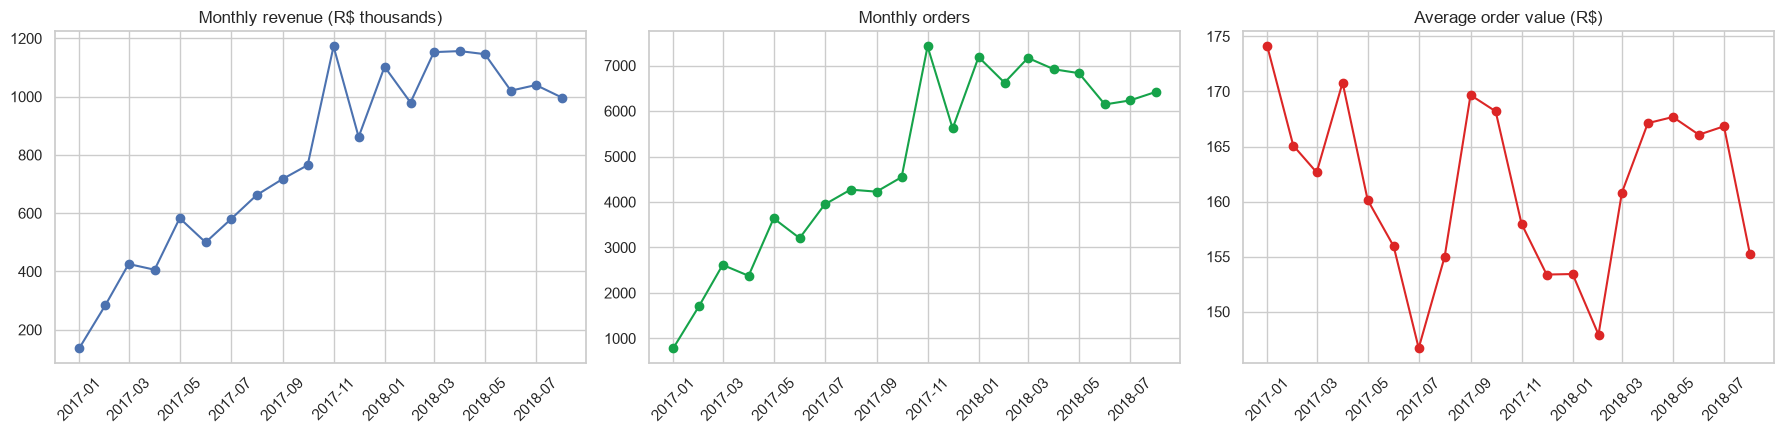

Revenue growth, Jan 2017 -> Aug 2018: 628%
Peak month: Nov 2017


In [4]:
# Cell 5: A.monthly revenue trend
tw = valid[valid["in_trend_window"]]
monthly = tw.groupby("purchase_month").agg(orders=("order_id", "count"),
                                           revenue=("revenue", "sum"),
                                           aov=("revenue", "mean"))
monthly["revenue_mom_pct"] = monthly["revenue"].pct_change() * 100
display(monthly)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(monthly.index, monthly["revenue"] / 1e3, marker="o"); axes[0].set_title("Monthly revenue (R$ thousands)")
axes[1].plot(monthly.index, monthly["orders"], marker="o", color="#16a34a"); axes[1].set_title("Monthly orders")
axes[2].plot(monthly.index, monthly["aov"], marker="o", color="#dc2626"); axes[2].set_title("Average order value (R$)")
for a in axes: a.tick_params(axis="x", rotation=45)
savefig("05_monthly_trends")

print(f"Revenue growth, Jan 2017 -> Aug 2018: {monthly['revenue'].iloc[-1] / monthly['revenue'].iloc[0] - 1:.0%}")
print("Peak month:", monthly["revenue"].idxmax().strftime("%b %Y"))

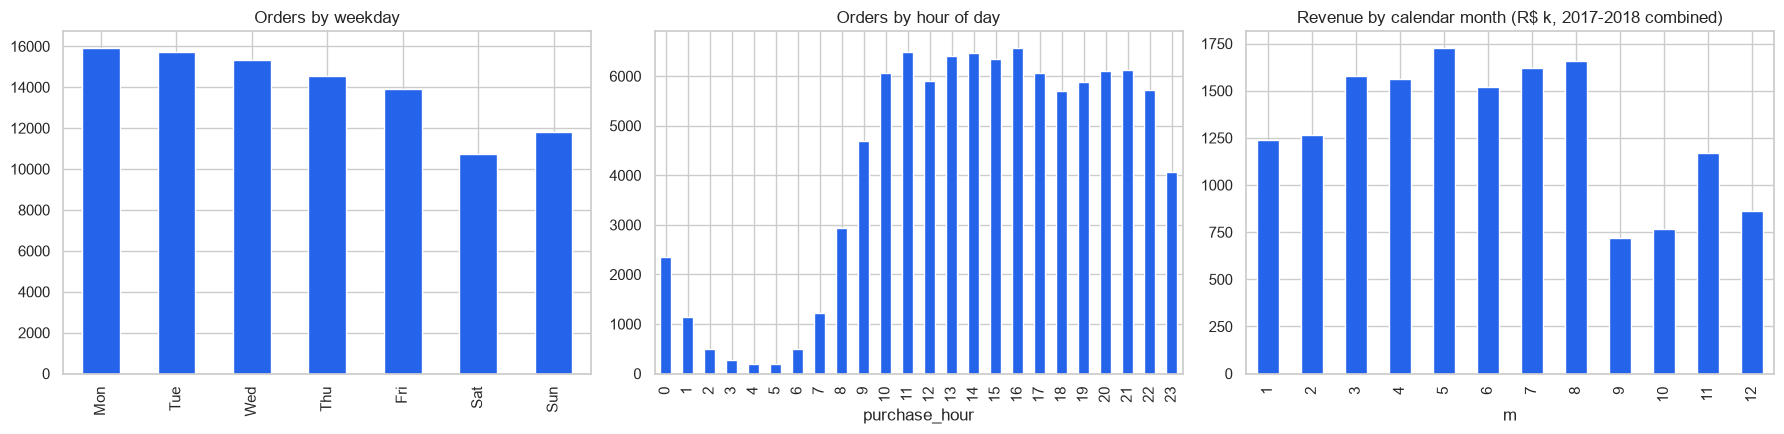

In [5]:
# Cell 6: seasonality (weekday and hour)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
dow = tw.groupby("purchase_dow")["order_id"].count()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot(kind="bar", ax=axes[0], color="#2563eb"); axes[0].set_title("Orders by weekday")

tw.groupby("purchase_hour")["order_id"].count().plot(kind="bar", ax=axes[1], color="#2563eb")
axes[1].set_title("Orders by hour of day")

tw.assign(m=tw["purchase_month"].dt.month).groupby("m")["revenue"].sum().div(1e3).plot(kind="bar", ax=axes[2], color="#2563eb")
axes[2].set_title("Revenue by calendar month (R$ k, 2017-2018 combined)")
savefig("05_seasonality")

Unique customers: 94982
Repeat customers (2+ orders): 2,887 (3.0%)


,customers
n_orders,
1,92095
2,2651
3,188
4,29
5,9
6,5


count   94,982.00
mean       165.70
std        226.75
min          9.59
50%        107.90
90%        318.97
99%      1,098.69
max     13,664.08
Name: spend, dtype: float64

Top 1% of customers -> 10.3% of revenue
Top 10% of customers -> 38.3% of revenue
Top 20% of customers -> 53.6% of revenue


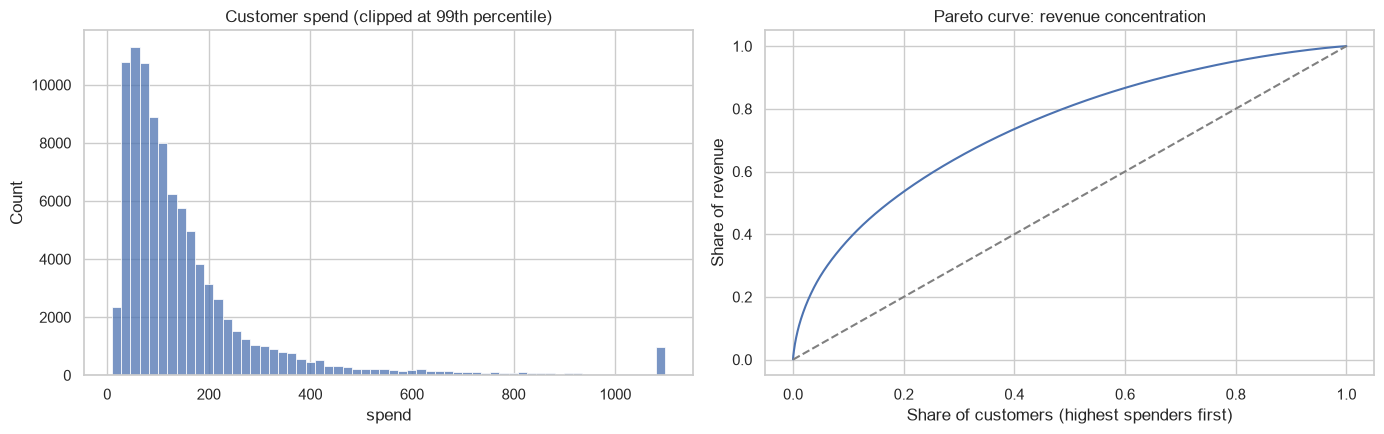

In [6]:
# Cell 7: B. customers, repeat purchase and Pareto

cust = valid.groupby("customer_unique_id").agg(n_orders=("order_id", "nunique"),
                                               spend=("revenue", "sum")).reset_index()

print("Unique customers:", len(cust))
print(f"Repeat customers (2+ orders): {(cust['n_orders'] > 1).sum():,} ({(cust['n_orders'] > 1).mean():.1%})")
display(cust["n_orders"].value_counts().sort_index().head(6).to_frame("customers"))
display(cust["spend"].describe(percentiles=[.5, .9, .99]))

cs = cust.sort_values("spend", ascending=False).reset_index(drop=True)
cs["cum_share"] = cs["spend"].cumsum() / cs["spend"].sum()
cs["cust_share"] = (cs.index + 1) / len(cs)
for p in [0.01, 0.10, 0.20]:
    print(f"Top {p:.0%} of customers -> {cs.loc[int(len(cs) * p) - 1, 'cum_share']:.1%} of revenue")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(cust["spend"].clip(upper=cust["spend"].quantile(0.99)), bins=60, ax=axes[0])
axes[0].set_title("Customer spend (clipped at 99th percentile)")
axes[1].plot(cs["cust_share"], cs["cum_share"]); axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("Pareto curve: revenue concentration")
axes[1].set_xlabel("Share of customers (highest spenders first)"); axes[1].set_ylabel("Share of revenue")
savefig("05_customer_spend_pareto")

customer_type,New,Returning,returning_pct
purchase_month,,,
2018-03-01,6951,217,3.03
2018-04-01,6706,213,3.08
2018-05-01,6590,243,3.56
2018-06-01,5932,213,3.47
2018-07-01,6041,192,3.08
2018-08-01,6214,207,3.22


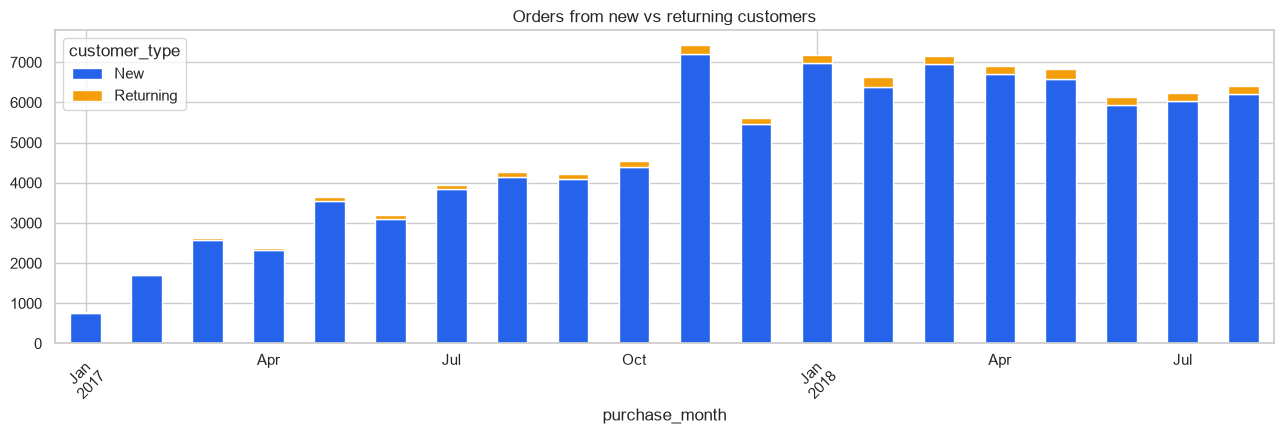

In [7]:
# Cell 8: B. new vs returning customers by month

v = valid.copy()
v["first_purchase"] = v.groupby("customer_unique_id")["order_purchase_timestamp"].transform("min")
v["customer_type"] = np.where(v["order_purchase_timestamp"] == v["first_purchase"], "New", "Returning")
mix = (v[v["in_trend_window"]].groupby(["purchase_month", "customer_type"]).size().unstack(fill_value=0))
mix["returning_pct"] = mix["Returning"] / (mix["New"] + mix["Returning"]) * 100
display(mix.tail(6))

mix[["New", "Returning"]].plot(kind="bar", stacked=True, figsize=(13, 4.5), color=["#2563eb", "#f59e0b"])
plt.title("Orders from new vs returning customers"); plt.xticks(rotation=45)
savefig("05_new_vs_returning")

,revenue,items_sold,orders,avg_price,avg_freight,revenue_share_pct,cum_share_pct
product_category_name_english,,,,,,,
health_beauty,"1,255,560.16",9631,8799,130.37,18.89,9.30,9.30
watches_gifts,"1,198,185.21",5970,5604,200.70,16.77,8.88,18.18
bed_bath_table,"1,035,964.06",11097,9399,93.36,18.42,7.68,25.86
sports_leisure,"979,740.92",8590,7673,114.06,19.50,7.26,33.12
computers_accessories,"904,322.02",7781,6654,116.22,18.84,6.70,39.82
furniture_decor,"727,465.05",8298,6425,87.67,20.75,5.39,45.21
housewares,"626,825.80",6915,5847,90.65,21.00,4.65,49.86
cool_stuff,"620,770.49",3779,3616,164.27,22.05,4.60,54.46
auto,"586,585.73",4204,3872,139.53,21.89,4.35,58.81


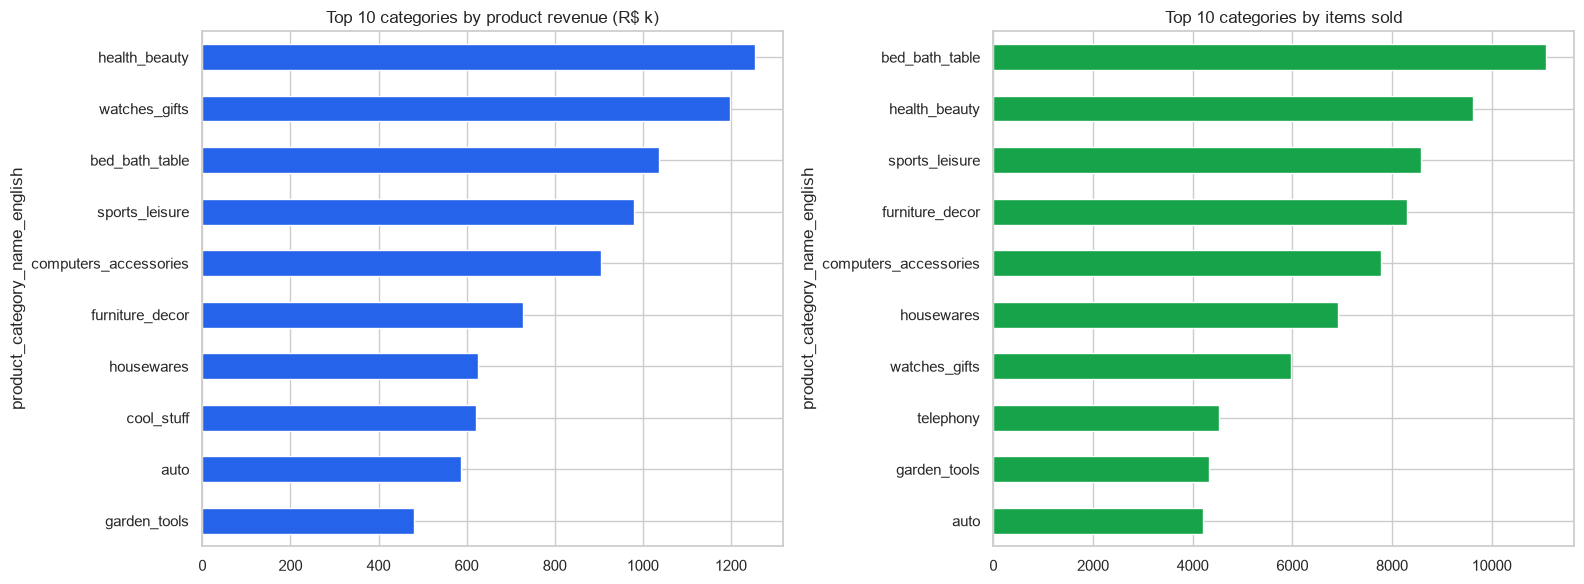

Categories: 74 | Categories making up 80% of revenue: 18

Lowest-revenue categories:


,revenue,items_sold,avg_price
product_category_name_english,,,
arts_and_craftmanship,"1,814.01",24,75.58
diapers_and_hygiene,"1,538.79",38,40.49
pc_gamer,"1,306.95",8,163.37
flowers,"1,110.04",33,33.64
home_comfort_2,760.27,30,25.34
cds_dvds_musicals,730.00,14,52.14
fashion_childrens_clothes,569.85,8,71.23
security_and_services,283.29,2,141.64


In [8]:
# Cell 9: C. product categories

cat = items_valid.groupby("product_category_name_english").agg(
    revenue=("price", "sum"), items_sold=("order_item_id", "count"),
    orders=("order_id", "nunique"), avg_price=("price", "mean"),
    avg_freight=("freight_value", "mean")).sort_values("revenue", ascending=False)
cat["revenue_share_pct"] = cat["revenue"] / cat["revenue"].sum() * 100
cat["cum_share_pct"] = cat["revenue_share_pct"].cumsum()
display(cat.head(10))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cat["revenue"].head(10).div(1e3).sort_values().plot(kind="barh", ax=axes[0], color="#2563eb")
axes[0].set_title("Top 10 categories by product revenue (R$ k)")
cat["items_sold"].sort_values(ascending=False).head(10).sort_values().plot(kind="barh", ax=axes[1], color="#16a34a")
axes[1].set_title("Top 10 categories by items sold")
savefig("05_top_categories")

print("Categories:", len(cat), "| Categories making up 80% of revenue:", (cat["cum_share_pct"] <= 80).sum() + 1)
print("\nLowest-revenue categories:")
display(cat.tail(8)[["revenue", "items_sold", "avg_price"]])

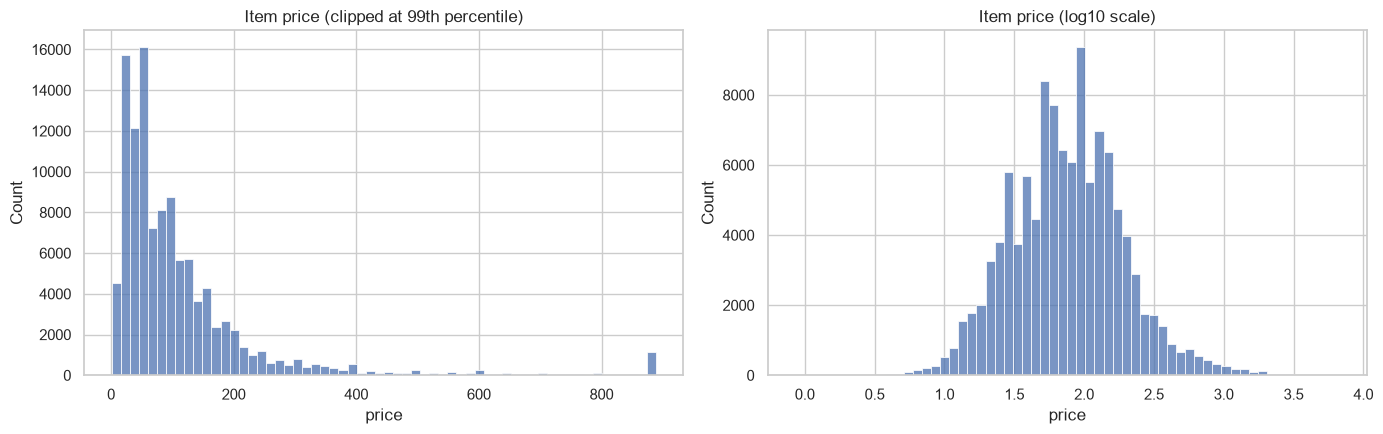

In [9]:
# Cell 10: C. price distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(items_valid["price"].clip(upper=items_valid["price"].quantile(0.99)), bins=60, ax=axes[0])
axes[0].set_title("Item price (clipped at 99th percentile)")
sns.histplot(np.log10(items_valid["price"]), bins=60, ax=axes[1]); axes[1].set_title("Item price (log10 scale)")
savefig("05_price_distribution")

,orders,revenue,customers,aov,order_share_pct
customer_state,,,,,
SP,41124,"5,878,702.01",39746,142.95,41.88
RJ,12697,"2,115,956.44",12241,166.65,12.93
MG,11496,"1,843,460.37",11134,160.36,11.71
RS,5415,"877,620.20",5233,162.07,5.51
PR,4982,"794,407.35",4824,159.46,5.07
SC,3599,"608,104.32",3501,168.96,3.67
BA,3344,"607,041.45",3244,181.53,3.41
DF,2120,"351,350.03",2057,165.73,2.16
ES,2018,"323,105.75",1950,160.11,2.06


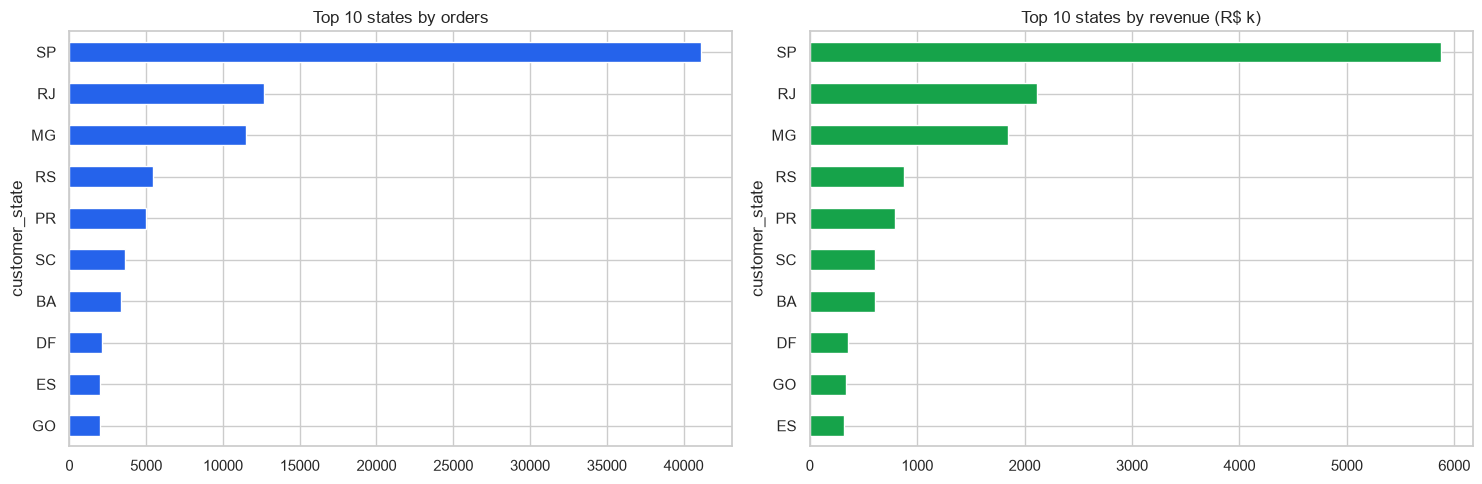

,orders
customer_city,
sao paulo,15291
rio de janeiro,6800
belo horizonte,2737
brasilia,2111
curitiba,1502
campinas,1422
porto alegre,1369
salvador,1234
guarulhos,1167


SP + RJ + MG share of orders: 66.5%


In [10]:
# Cell 11: D. geography

geo = valid.groupby("customer_state").agg(orders=("order_id", "count"), revenue=("revenue", "sum"),
                                          customers=("customer_unique_id", "nunique"), aov=("revenue", "mean"))
geo["order_share_pct"] = geo["orders"] / geo["orders"].sum() * 100
geo = geo.sort_values("orders", ascending=False)
display(geo.head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
geo["orders"].head(10).sort_values().plot(kind="barh", ax=axes[0], color="#2563eb"); axes[0].set_title("Top 10 states by orders")
geo["revenue"].sort_values(ascending=False).head(10).div(1e3).sort_values().plot(kind="barh", ax=axes[1], color="#16a34a")
axes[1].set_title("Top 10 states by revenue (R$ k)")
savefig("05_states_orders_revenue")

top_cities = valid.groupby("customer_city")["order_id"].count().sort_values(ascending=False).head(10)
display(top_cities.to_frame("orders"))
print(f"SP + RJ + MG share of orders: {geo.loc[['SP', 'RJ', 'MG'], 'order_share_pct'].sum():.1f}%")

,orders,avg_delivery_days,late_rate,avg_review
customer_state,,,,
SP,40494,8.76,5.89,4.25
PR,4923,11.99,5.00,4.24
MG,11354,12.01,5.61,4.19
DF,2080,12.97,7.07,4.13
SC,3546,14.95,9.76,4.13
RS,5344,15.30,7.15,4.18
RJ,12350,15.31,13.47,3.97
GO,1957,15.61,8.18,4.11
MS,701,15.62,11.55,4.16


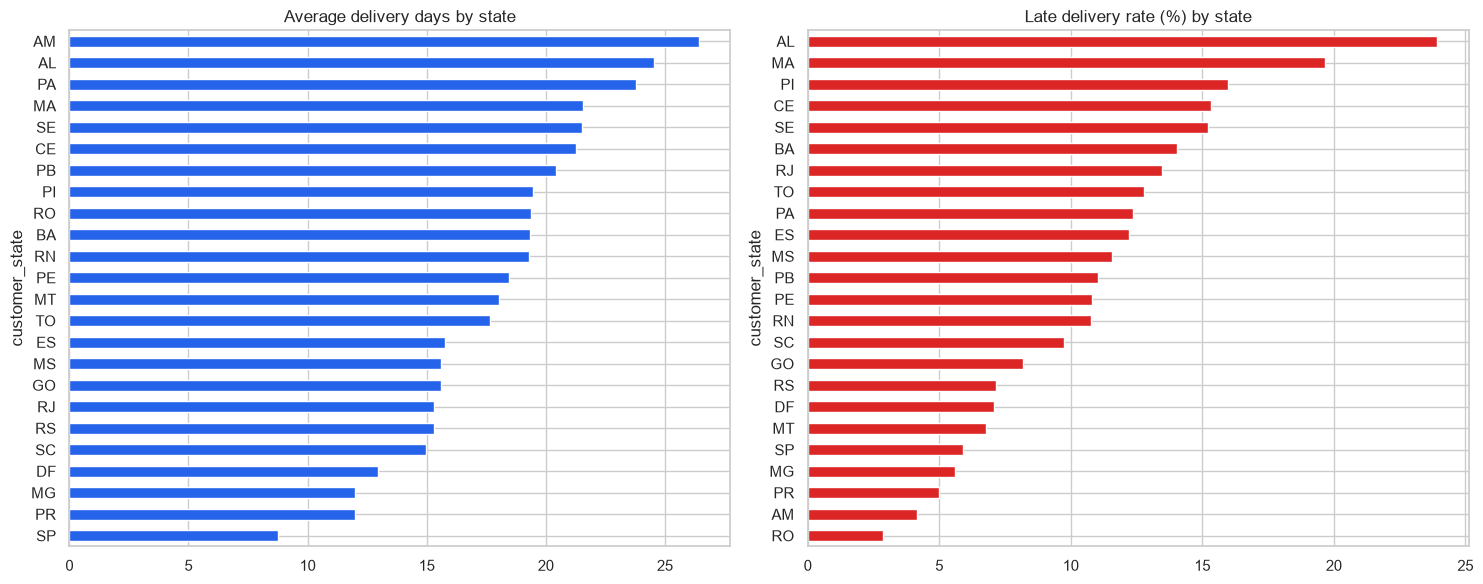

In [11]:
# Cell 12: E. delivery performance by state

state = deliv.groupby("customer_state").agg(orders=("order_id", "count"),
                                            avg_delivery_days=("delivery_days", "mean"),
                                            late_rate=("is_late", "mean"),
                                            avg_review=("review_score", "mean"))
state = state[state["orders"] >= 100].sort_values("avg_delivery_days")
state["late_rate"] *= 100
display(state)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
state["avg_delivery_days"].plot(kind="barh", ax=axes[0], color="#2563eb"); axes[0].set_title("Average delivery days by state")
state["late_rate"].sort_values().plot(kind="barh", ax=axes[1], color="#dc2626"); axes[1].set_title("Late delivery rate (%) by state")
savefig("05_delivery_by_state")

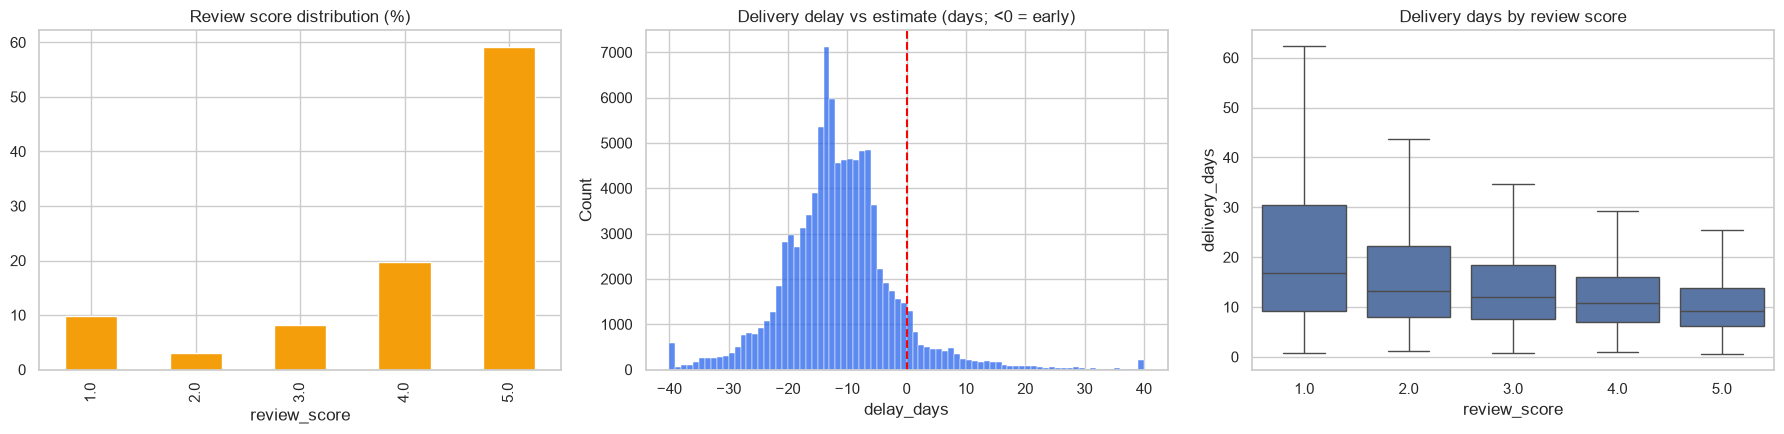

Delivered early or on time: 91.9%
Median days earlier than estimate: 11.9


,count,mean,median
is_late,,,
0.00,88163,4.29,5.00
1.00,7661,2.57,2.00


In [12]:
# Cell 13: E. delivery and reviews overview

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
deliv["review_score"].value_counts(normalize=True).sort_index().mul(100).plot(kind="bar", ax=axes[0], color="#f59e0b")
axes[0].set_title("Review score distribution (%)")

sns.histplot(deliv["delay_days"].clip(-40, 40), bins=80, ax=axes[1], color="#2563eb")
axes[1].axvline(0, color="red", ls="--"); axes[1].set_title("Delivery delay vs estimate (days; <0 = early)")

sns.boxplot(data=deliv.dropna(subset=["review_score"]), x="review_score", y="delivery_days", ax=axes[2], showfliers=False)
axes[2].set_title("Delivery days by review score")
savefig("05_delivery_reviews")

print(f"Delivered early or on time: {(deliv['is_late'] == 0).mean():.1%}")
print(f"Median days earlier than estimate: {-deliv['delay_days'].median():.1f}")
display(deliv.groupby("is_late")["review_score"].agg(["count", "mean", "median"]))

Sellers: 2970 | with 30+ orders: 627


,orders,late_rate,avg_delay_days,revenue,seller_state
seller_id,,,,,
ede0c03645598cdfc63ca8237acbe73d,43,34.04,-3.48,"2,352.15",SP
54965bbe3e4f07ae045b90b0b8541f52,73,32.10,-1.69,"10,351.70",PR
ad781527c93d00d89a11eecd9dcad7c1,38,31.58,-8.31,"6,039.63",SP
835f0f7810c76831d6c7d24c7a646d4d,42,31.25,-4.97,"4,990.20",SP
2a1348e9addc1af5aaa619b1a3679d6b,48,29.41,1.35,"2,697.40",MG
66e0557ecc2b4dbea057e93f215f68d8,30,26.67,-8.13,"12,141.00",SP
71039d19d4303bf9054d69e9a9236699,35,26.32,-6.55,"3,537.20",SP
6039e27294dc75811c0d8a39069f52c0,63,25.68,-6.37,"13,500.80",SP
ef990a83bbea832f36ebe81376335aa8,43,25.00,-7.81,"4,642.59",SC


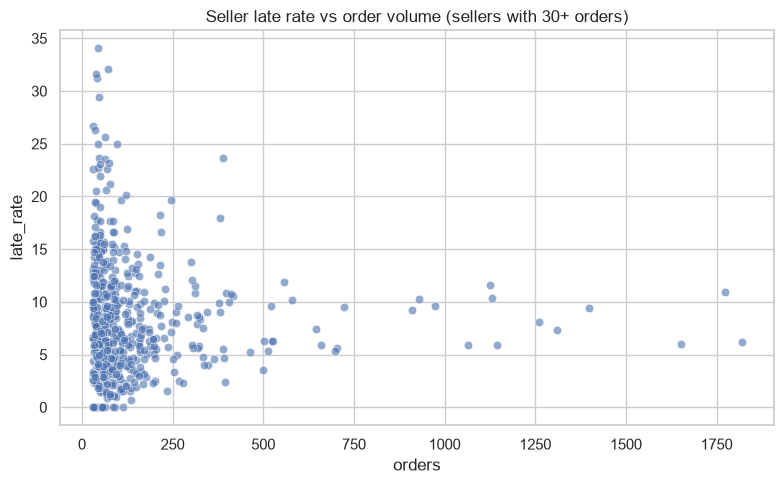

In [13]:
# Cell 14: E. seller delivery performance

iv = items_valid[items_valid["in_delivery_analysis"].fillna(False)].copy()
iv["is_late"] = iv["is_late"].astype(float)

seller = iv.groupby("seller_id").agg(orders=("order_id", "nunique"), late_rate=("is_late", "mean"),
                                     avg_delay_days=("delay_days", "mean"), revenue=("price", "sum"),
                                     seller_state=("seller_state", "first"))
seller["late_rate"] *= 100
eligible = seller[seller["orders"] >= 30]
print("Sellers:", len(seller), "| with 30+ orders:", len(eligible))
display(eligible.sort_values("late_rate", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=eligible, x="orders", y="late_rate", alpha=0.6, ax=ax)
ax.set_title("Seller late rate vs order volume (sellers with 30+ orders)")
savefig("05_seller_late_rate")

In [14]:
# Cell 15: sellers with high late rate
print("Sellers with late rate > 20%:", (eligible["late_rate"] > 20).sum(), "of", len(eligible))

Sellers with late rate > 20%: 23 of 627


## Key EDA findings
**Revenue:** R$15.74M from 98,198 valid orders. Monthly revenue grew from R$137k (Jan 2017) to R$997k (Aug 2018), +628%, driven by order volume (AOV stable at R$147-174). Growth plateaued at about R$1.0-1.15M/month from 2018. Peak month: Nov 2017 (R$1.17M, +53% vs Oct, Black Friday), then -26.5% in December.
**Seasonality:** Orders peak Mon-Tue, lowest on Saturday; most activity 10:00-22:00. Calendar-month totals are not comparable (Sep-Dec have only 2017 data).
**Customers:** 3.0% repeat (2,887 of 94,982); returning share flat at 3-3.6% per month. Top 10% of customers = 38.3% of revenue, top 20% = 53.6%. AOV R$160 vs median R$105 (right-skewed).
**Products:** Top categories by revenue are health_beauty (R$1.26M, 9.3%), watches_gifts (R$1.20M, 8.9%) and bed_bath_table (R$1.04M, 7.7%); the top 10 make up 62% of revenue. bed_bath_table sells the most items (11,097) but at a low average price (R$93), while watches_gifts earns more from fewer items (5,970 at R$201 average). 18 of 74 categories make up 80% of revenue; the lowest categories (for example security_and_services, 2 items) are negligible.
**Geography:** SP+RJ+MG = 66.5% of orders (SP 41.9%). Highest late rates: AL 23.9%, MA 19.7%, PI 16.0%; RJ (13.5%) and BA (14.0%) are high-volume states with elevated late rates.
**Delivery and reviews:** 8.1% late; median order arrives 11.9 days early; late orders average 2.57 stars vs 4.29 on time. Estimates are padded more for distant states (AM: slowest but 4.1% late).
**Sellers:** 23 of 627 sellers with 30+ orders (3.7%) have a late rate above 20%, and the worst reach 30-34%. Sellers with 500+ orders stay at 5-12%, so the worst delays come from small and mid-size sellers.
**Questions answered:** 1, 2, 4 and 6 fully; 3 partly (concentration; completed with RFM in notebook 8); 7 previewed here and tested formally in notebooks 7 and 10.